# Mini proyecto – Análisis de datos pesqueros
## Exploracion datos de pesca

**Autor:** Anthony Rojas  
**Fecha:** Noviembre 2026

Análisis exploratorio de registros de prospección pesquera en el Archipiélago de San Andrés y Providencia. 

In [12]:
# Cargar liberias y modulos necesarios

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os



In [13]:
#Verificar el directorio actual

import os
print("Directorio actual:", os.getcwd())
print("\nContenido de la carpeta actual:")
print(os.listdir())

Directorio actual: /home/jovyan/Hackaton_ARA/Actividad_Final

Contenido de la carpeta actual:
['.ipynb_checkpoints', 'figuras', 'Untitled.ipynb', 'Figuras', 'Datos']


In [14]:
# Cargar datos
df = pd.read_csv("Datos/T_Maestra_Prov_Convertido.csv")
print(f"Datos cargados: {df.shape[0]} filas, {df.shape[1]} columnas")
df.head()

Datos cargados: 11032 filas, 33 columnas


,CODIGO,REGISTRO,ARTE,METODO,ANO_ZARPE,MES_ZARPE,DIA_ZARPE,ANO_ARRIBO,MES_ARRIBO,DIA_ARRIBO,...,GRUPO,SUBGRUPO,Clasificacio,NOM_CIENTIF,NOM_VULGAR,ESTADO,PESO,CT_KG,GASTOS,CPUE
0,12080001,1,BUCEO,NaN,2012,8,6,2012,8,6,...,PECES,OTROS PELÁGICOS,ROJO,Sphyraena barracuda,BARRACUDA,EVISC CON ESCAMA,2.0,21.5,60500.0,2.0
1,12080001,1,BUCEO,NaN,2012,8,6,2012,8,6,...,PECES,DEMERSAL SOMERO,ROJO,Mycteroperca bonaci,BLACK GROUPER,EVISC CON ESCAMA,3.5,NaN,NaN,3.5
2,12080001,1,BUCEO,NaN,2012,8,6,2012,8,6,...,PECES,DEMERSAL SOMERO,ROJO,Lutjanus jocu,DOGTEETH SNAPPER,EVISC CON ESCAMA,5.0,NaN,NaN,5.0
3,12080001,1,BUCEO,NaN,2012,8,6,2012,8,6,...,PECES,DEMERSAL SOMERO,ROJO,Lachnolaimus maximus,HOG FISH,EVISC CON ESCAMA,4.0,NaN,NaN,4.0
4,12080001,1,BUCEO,NaN,2012,8,6,2012,8,6,...,PECES,DEMERSAL SOMERO,ROJO,Haemulon album,MARGATE,EVISC CON ESCAMA,2.5,NaN,NaN,2.5


## Exploración básica

In [15]:
print("Información general:")
print(df.info())

print("\nResumen estadístico de variables numéricas principales:")
print(df[["PESO", "CPUE"]].describe())

print("\nEspecies únicas:", df["NOM_VULGAR"].nunique())

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 11032 entries, 0 to 11031
Data columns (total 33 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   CODIGO        11032 non-null  int64  
 1   REGISTRO      11032 non-null  int64  
 2   ARTE          11032 non-null  str    
 3   METODO        5275 non-null   str    
 4   ANO_ZARPE     11032 non-null  int64  
 5   MES_ZARPE     11032 non-null  int64  
 6   DIA_ZARPE     11032 non-null  int64  
 7   ANO_ARRIBO    11032 non-null  int64  
 8   MES_ARRIBO    11032 non-null  int64  
 9   DIA_ARRIBO    11032 non-null  int64  
 10  SITIO         11032 non-null  str    
 11  REGISTRADOR   11032 non-null  str    
 12  EMBARCACION   11032 non-null  str    
 13  PESCADORES    11032 non-null  int64  
 14  PROPULSION    11032 non-null  str    
 15  MOTORES       11032 non-null  int64  
 16  POTENCIA      11032 non-null  float64
 17  AREA          11032 non-null  str    
 18  SUBAREA       11

## Función propia

In [19]:
def resumen_captura(data, especie=None):
    """
    Calcula el peso total y el CPUE promedio de las capturas.
    
    Parámetros
    ----------
    data : pandas.DataFrame
        Tabla de datos de prospección.
    especie : str, opcional
        Nombre vulgar de la especie. Si es None, usa todos los registros.
    
    Retorna
    -------
    dict
        Diccionario con 'peso_total' y 'cpue_promedio'.
    """
    df_filtro = data.copy()
    if especie is not None:
        df_filtro = df_filtro[df_filtro["NOM_VULGAR"] == especie]
    
    return {
        "peso_total": round(df_filtro["PESO"].sum(), 2),
        "cpue_promedio": round(df_filtro["CPUE"].mean(), 2)
    }


def captura_por_año(data, especie=None, metrica="PESO"):
    """
    Calcula la captura total (suma) o el CPUE promedio por año.
    
    Parámetros
    ----------
    data : pandas.DataFrame
    especie : str, opcional
    metrica : str
        "PESO" para suma, "CPUE" para media.
    
    Retorna
    -------
    pandas.Series
    """
    df_filtro = data.copy()
    if especie is not None:
        df_filtro = df_filtro[df_filtro["NOM_VULGAR"] == especie]
    
    if metrica == "PESO":
        return df_filtro.groupby("ANO_ZARPE")["PESO"].sum().sort_index()
    else:
        return df_filtro.groupby("ANO_ZARPE")["CPUE"].mean().sort_index()


def tabla_estadisticos(data, columnas=["PESO", "CPUE"]):
    """
    Genera tabla con media, mediana y desviación estándar.
    """
    stats = data[columnas].agg(["mean", "median", "std"]).round(2)
    stats.index = ["Media", "Mediana", "Desviación estándar"]
    return stats

In [20]:
print("Resumen general:")
print(resumen_captura(df))

print("\nResumen BARRACUDA:")
print(resumen_captura(df, "BARRACUDA"))

print("\nEstadísticos generales:")
display(tabla_estadisticos(df))

print("\nEstadísticos BARRACUDA:")
display(tabla_estadisticos(df[df["NOM_VULGAR"] == "BARRACUDA"]))

Resumen general:
{'peso_total': np.float64(180249.74), 'cpue_promedio': np.float64(12.22)}

Resumen BARRACUDA:
{'peso_total': np.float64(6169.0), 'cpue_promedio': np.float64(10.16)}

Estadísticos generales:


,PESO,CPUE
Media,16.34,12.22
Mediana,5.00,5.00
Desviación estándar,201.86,94.39



Estadísticos BARRACUDA:


,PESO,CPUE
Media,10.53,10.16
Mediana,5.25,5.00
Desviación estándar,31.14,30.72


## Visualizaciones

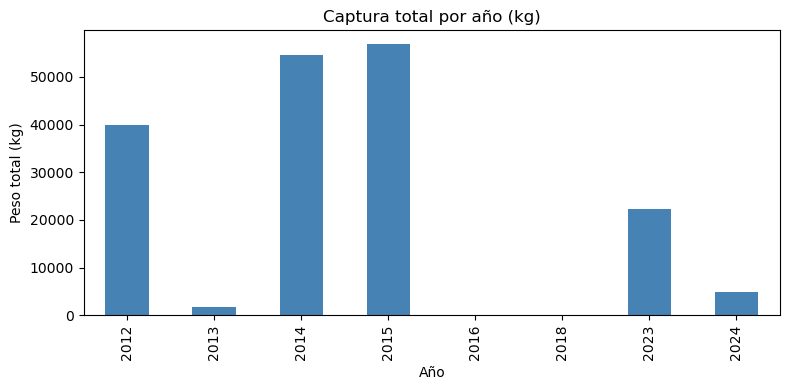

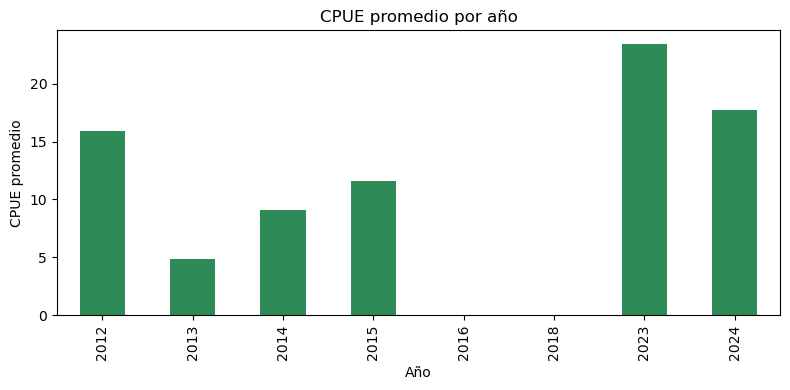

<Figure size 1200x600 with 0 Axes>

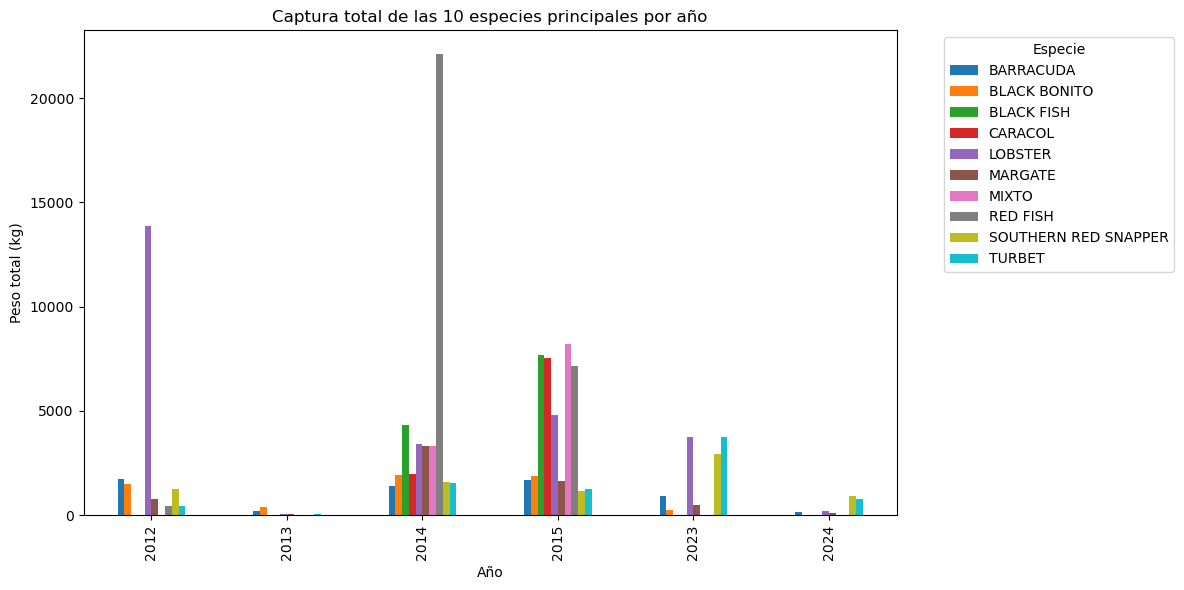

<Figure size 1200x600 with 0 Axes>

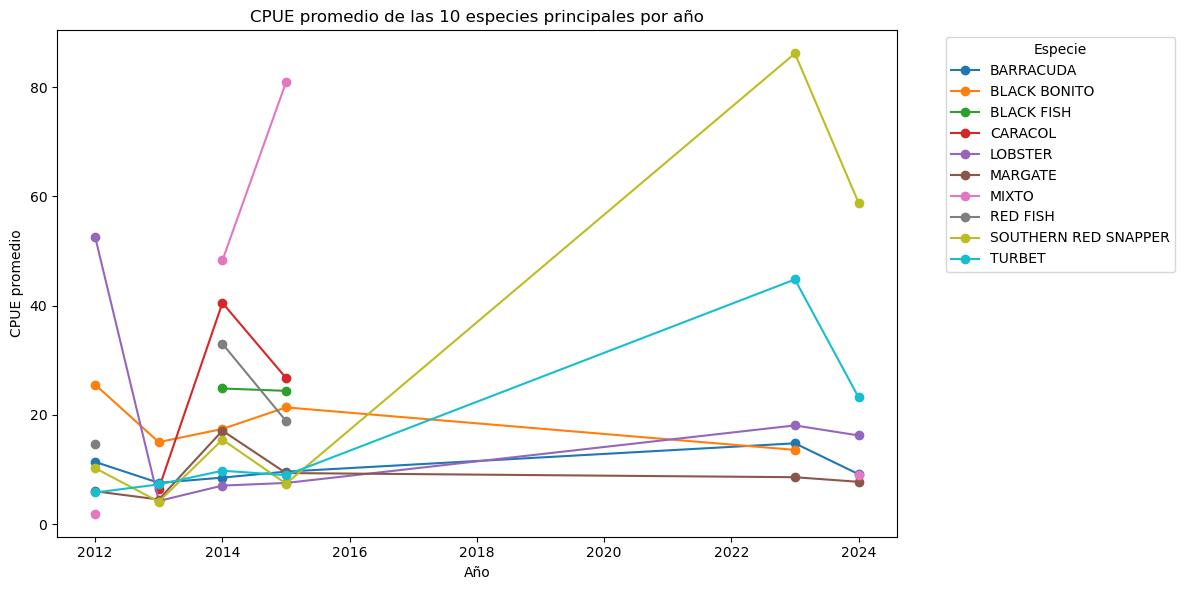

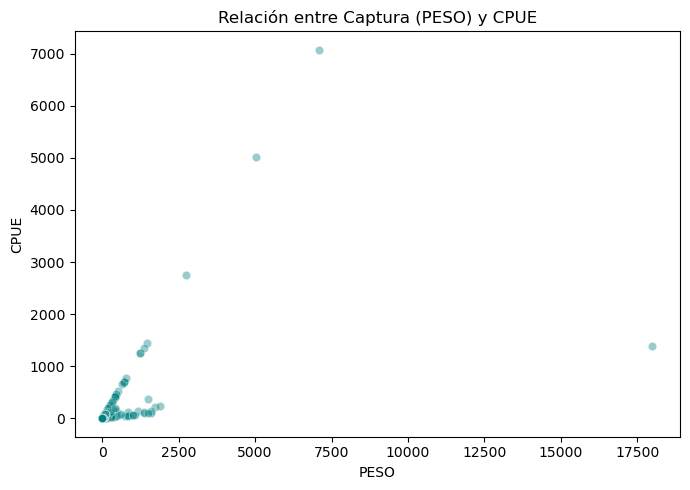

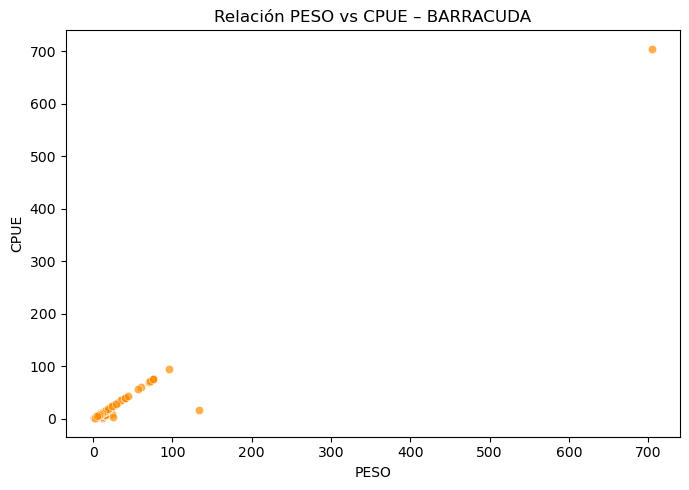

Todos los gráficos fueron guardados en la carpeta Figuras/


In [21]:
# Captura total por año
captura_anual = captura_por_año(df, metrica="PESO")
plt.figure(figsize=(8, 4))
captura_anual.plot(kind="bar", color="steelblue")
plt.title("Captura total por año (kg)")
plt.xlabel("Año")
plt.ylabel("Peso total (kg)")
plt.tight_layout()
plt.savefig("Figuras/captura_total_por_año.png", dpi=150)
plt.show()

# CPUE promedio por año
cpue_anual = captura_por_año(df, metrica="CPUE")
plt.figure(figsize=(8, 4))
cpue_anual.plot(kind="bar", color="seagreen")
plt.title("CPUE promedio por año")
plt.xlabel("Año")
plt.ylabel("CPUE promedio")
plt.tight_layout()
plt.savefig("Figuras/cpue_promedio_por_año.png", dpi=150)
plt.show()

# Top 10 especies – Captura por año
top10 = df.groupby("NOM_VULGAR")["PESO"].sum().nlargest(10).index
captura_top10 = (df[df["NOM_VULGAR"].isin(top10)]
                 .groupby(["ANO_ZARPE", "NOM_VULGAR"])["PESO"]
                 .sum().unstack(fill_value=0))

plt.figure(figsize=(12, 6))
captura_top10.plot(kind="bar", stacked=False, colormap="tab10", figsize=(12, 6))
plt.title("Captura total de las 10 especies principales por año")
plt.xlabel("Año")
plt.ylabel("Peso total (kg)")
plt.legend(title="Especie", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig("Figuras/top10_captura_por_año.png", dpi=150, bbox_inches="tight")
plt.show()

# Top 10 especies – CPUE por año
cpue_top10 = (df[df["NOM_VULGAR"].isin(top10)]
              .groupby(["ANO_ZARPE", "NOM_VULGAR"])["CPUE"]
              .mean().unstack())

plt.figure(figsize=(12, 6))
cpue_top10.plot(kind="line", marker="o", figsize=(12, 6))
plt.title("CPUE promedio de las 10 especies principales por año")
plt.xlabel("Año")
plt.ylabel("CPUE promedio")
plt.legend(title="Especie", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig("Figuras/top10_cpue_por_año.png", dpi=150, bbox_inches="tight")
plt.show()

# Relación PESO vs CPUE
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="PESO", y="CPUE", alpha=0.4, color="teal")
plt.title("Relación entre Captura (PESO) y CPUE")
plt.tight_layout()
plt.savefig("Figuras/relacion_peso_cpue.png", dpi=150)
plt.show()

# Relación para una especie
especie = "BARRACUDA"
df_esp = df[df["NOM_VULGAR"] == especie]
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_esp, x="PESO", y="CPUE", alpha=0.7, color="darkorange")
plt.title(f"Relación PESO vs CPUE – {especie}")
plt.tight_layout()
plt.savefig(f"Figuras/relacion_peso_cpue_{especie}.png", dpi=150)
plt.show()

print("Todos los gráficos fueron guardados en la carpeta Figuras/")

In [22]:
# Tabla resumen Top 10

resumen_especies = (df.groupby("NOM_VULGAR")
                    .agg(captura_total=("PESO", "sum"),
                         cpue_promedio=("CPUE", "mean"),
                         registros=("PESO", "count"))
                    .round(2)
                    .sort_values("captura_total", ascending=False)
                    .head(10))

print("Top 10 especies:")
display(resumen_especies)

Top 10 especies:


,captura_total,cpue_promedio,registros
NOM_VULGAR,,,
RED FISH,29751.00,22.40,374
LOBSTER,26091.77,16.15,1608
BLACK FISH,12023.63,24.48,367
MIXTO,11560.00,65.80,85
CARACOL,9534.00,28.06,53
TURBET,7880.36,15.73,497
SOUTHERN RED SNAPPER,7876.86,19.43,321
MARGATE,6440.78,10.93,576
BARRACUDA,6169.00,10.16,586


## Conclusiones

- Se analizaron los registros de Desembarque de la pesca artesanal del Archipiélago de San Andrés y Providencia.
- Las especies más frecuentes pertenecen principalmente a grupos demersales y pelágicos.
- La función `resumen_captura` permite obtener de forma rápida el peso total y el CPUE promedio, con opción de filtrar por especie.
- Existe variabilidad en el peso de las capturas y en el CPUE entre faenas.
- Los gráficos generados facilitan la identificación de patrones y valores extremos en las variables principales.